# EDA (ANALISE EXPLORATORIA DE DADOS)
Objetivo: entender os dados de treino e teste antes de modelar: estrutura, valores faltantes, distribuição da qualidade, correlações e formato das features.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregamento e informações básicas

In [3]:
df = pd.read_csv("../data/train.csv")
df_test = pd.read_csv("../data/test.csv")
df.head()

,id,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0,9.3,0.40,0.34,2.1,0.088,14.0,28.0,0.99940,3.44,0.84,12.2,7.0
1,1,8.3,0.38,0.33,1.8,0.070,5.0,15.0,0.99820,3.39,0.55,9.9,5.0
2,2,6.6,0.28,0.30,2.1,0.068,8.0,17.0,0.99552,3.51,0.80,10.7,6.0
3,3,8.2,0.35,0.36,2.6,0.086,14.0,89.0,0.99910,3.23,0.67,9.5,5.0
4,4,10.9,0.18,0.49,1.8,0.084,21.0,77.0,0.99658,3.20,0.63,9.5,6.0


In [4]:
print("Shape do teste:", df_test.shape)
print("\nNulos no teste:\n", df_test.isnull().sum())
print("\nDuplicatas no teste:", df_test.drop(columns=["id"]).duplicated().sum())

Shape do teste: (10000, 12)

Nulos no teste:
 id                         0
fixed acidity           2000
volatile acidity        2000
citric acid             2000
residual sugar          2000
chlorides               2000
free sulfur dioxide     2000
total sulfur dioxide    2000
density                 2000
pH                      2000
sulphates               2000
alcohol                 2000
dtype: int64

Duplicatas no teste: 0


O test.csv tem 2.000 nulos em cada feature, exatamente 20% de 10.000.

In [5]:
df_test.isnull().sum(axis=1).value_counts()

2    3002
1    2359
3    2200
4    1101
0     838
5     384
6     104
7       8
8       3
9       1
Name: count, dtype: int64

A quantidade de nulos por linha segue de perto uma distribuição binomial (n = 11, p = 0,2), o que indica que os nulos foram sorteados de forma aleatória e independente (MCAR). Apenas 838 linhas (8,4%) estão completas, então remover linhas com nulos não é viável. A maioria das linhas tem mais de um nulo, o que justifica uma imputação iterativa.

In [6]:
df.shape


(15000, 13)

O treino tem 15.000 linhas e 13 colunas: id, 11 features físico-químicas e o alvo quality.O teste tem 10.000 linhas e não tem a coluna quality.

In [7]:
df.dtypes

id                        int64
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                 float64
dtype: object

In [8]:
df.isnull().sum()

id                      0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [9]:
df.drop(columns=["id"]).duplicated().sum()

np.int64(0)

Ou seja, não tem valores nulos e nem linhas duplicadas. 


# Estatísticas Descritivas

In [10]:
df.drop(columns=["id"]).describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,8.141927,0.505266,0.231299,2.189266,0.078641,13.234033,37.178500,0.996915,3.320703,0.618600,10.187160,5.660600
std,1.381534,0.134270,0.176764,0.505553,0.013768,7.916878,24.034172,0.001399,0.115140,0.105734,0.912091,0.804892
min,4.600000,0.120000,0.000000,1.100000,0.012000,1.000000,5.000000,0.990640,2.880000,0.390000,6.400000,3.000000
25%,7.200000,0.400000,0.050000,1.900000,0.073000,6.000000,20.000000,0.995900,3.240000,0.550000,9.500000,5.000000
50%,7.800000,0.510000,0.240000,2.100000,0.078000,12.000000,31.000000,0.996800,3.320000,0.600000,9.800000,6.000000
75%,8.900000,0.600000,0.380000,2.400000,0.083000,17.000000,48.000000,0.997800,3.390000,0.660000,10.800000,6.000000
max,15.800000,1.580000,0.740000,11.000000,0.415000,53.000000,289.000000,1.003690,3.780000,1.950000,14.100000,8.000000


# Variável Alvo : Qualidade (quality)

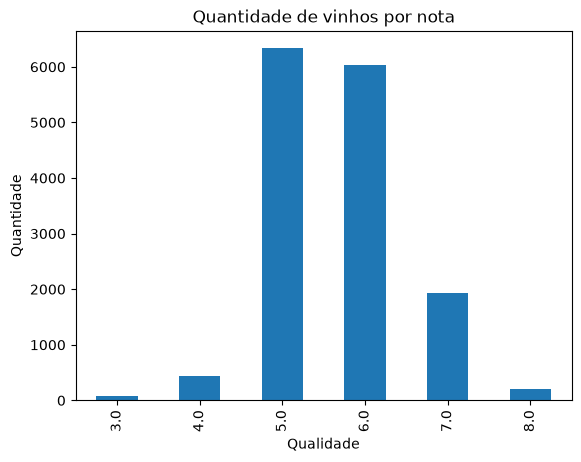

In [11]:
df["quality"].value_counts().sort_index().plot(kind="bar")
plt.title("Quantidade de vinhos por nota")
plt.xlabel("Qualidade")
plt.ylabel("Quantidade")
plt.show()

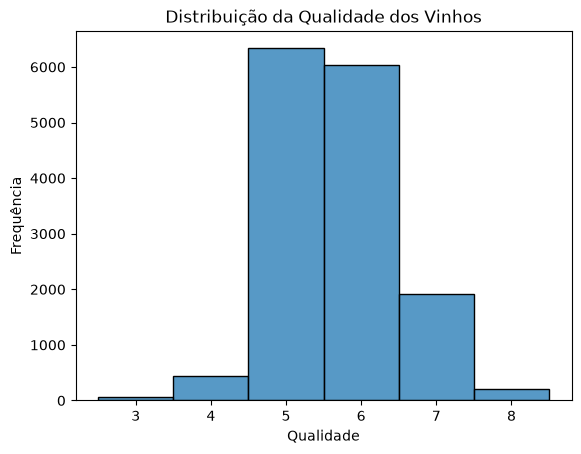

In [12]:
sns.histplot(data=df, x="quality",discrete=True)
plt.title("Distribuição da Qualidade dos Vinhos")
plt.xlabel("Qualidade")
plt.ylabel("Frequência")

plt.show()

Tiramos disso, que a maioria dos vinhos do dataset são de notas 5 e 6. A distribuição da qualidade é desbalanceada.Um modelo de regressão, por exemplo, vai tender a prever valores perto de 5,5–6 e errar nos extremos.




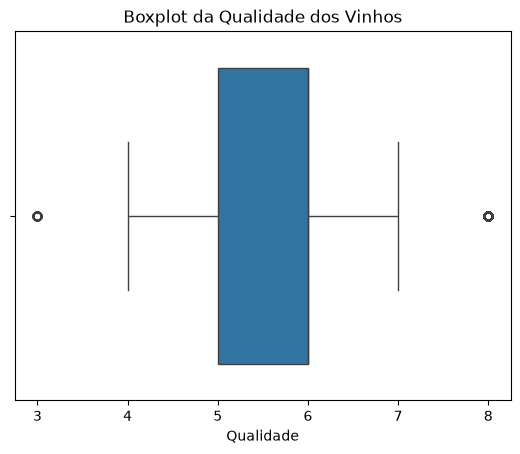

In [13]:
sns.boxplot(data=df, x="quality")

plt.title("Boxplot da Qualidade dos Vinhos")
plt.xlabel("Qualidade")
plt.show()

Pelo critério do IQR (Q1 = 5, Q3 = 6, limites em 3.5 e 7.5), as notas 3 e 8 aparecem como outliers. Porém não são erros: são avaliações legítimas, apenas raras (70 e 202 vinhos, respectivamente), consequência do desbalanceamento da variável alvo. Por isso serão mantidas. O efeito esperado é que o modelo erre mais nessas notas extremas.

# Correlação

In [14]:
df_corr = df.drop(columns=['id'])
correlacao = df_corr.corr(method='pearson')

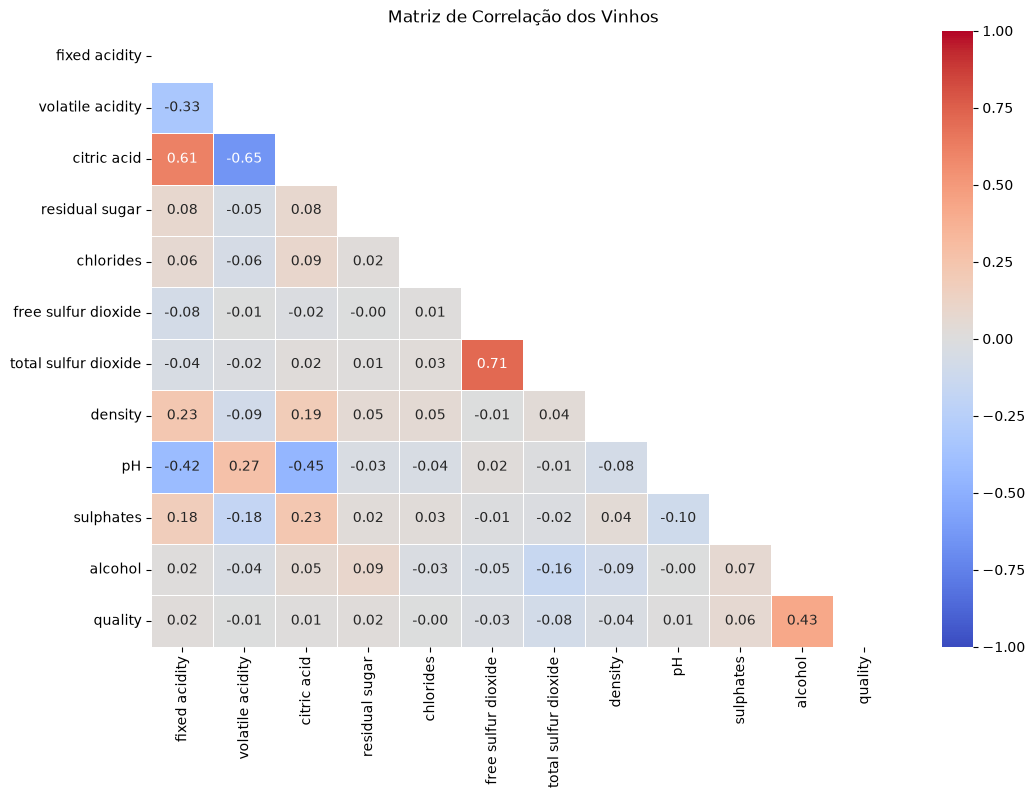

In [15]:
mascara = np.triu(np.ones_like(correlacao, dtype=bool))

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlacao,
    mask=mascara,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5
)
plt.title('Matriz de Correlação dos Vinhos')
plt.show()

# Correlação de cada feature com a qualidade

total sulfur dioxide   -0.082
density                -0.035
free sulfur dioxide    -0.026
volatile acidity       -0.007
chlorides              -0.002
pH                      0.007
citric acid             0.015
fixed acidity           0.019
residual sugar          0.022
sulphates               0.063
alcohol                 0.427
Name: quality, dtype: float64


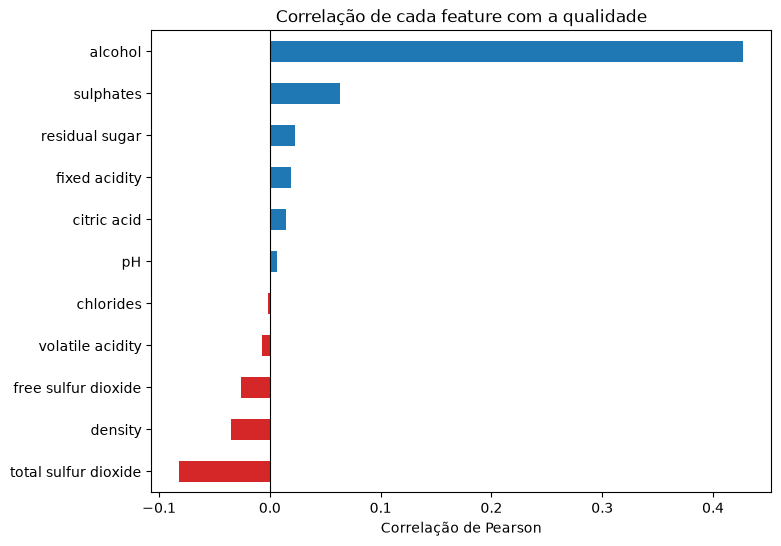

In [16]:
corr_quality = correlacao["quality"].drop("quality").sort_values()
print(corr_quality.round(3))

cores = ["tab:red" if v < 0 else "tab:blue" for v in corr_quality]
corr_quality.plot(kind="barh", color=cores, figsize=(8, 6))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlação de cada feature com a qualidade")
plt.xlabel("Correlação de Pearson")
plt.show()

Correlação com a qualidade. Apenas alcohol tem correlação relevante com a qualidade (≈ 0,43): vinhos com mais álcool tendem a receber notas maiores. Todas as outras features ficam entre -0,1 e 0,1, ou seja, praticamente sem relação linear. As mais fortes entre elas são total sulfur dioxide (≈ -0,08) e sulphates (≈ 0,06), mas ainda são valores muito baixos. Isso indica que um modelo linear vai depender quase só de alcohol, e que o desempenho da Etapa 2 deve ficar limitado, o que é compatível com o critério de sucesso modesto do desafio (R² > 0,35).

# Pares de features mais correlacionadas entre si

In [17]:
corr_features = correlacao.drop(index="quality", columns="quality")
mascara_baixo = np.tril(np.ones_like(corr_features, dtype=bool), k=-1)  # cada par só uma vez
pares = corr_features.where(mascara_baixo).stack()
top_pares = pares.reindex(pares.abs().sort_values(ascending=False).index)
print(top_pares.head(10).round(3))

total sulfur dioxide  free sulfur dioxide    0.715
citric acid           volatile acidity      -0.652
                      fixed acidity          0.614
pH                    citric acid           -0.454
                      fixed acidity         -0.416
volatile acidity      fixed acidity         -0.330
pH                    volatile acidity       0.270
density               fixed acidity          0.231
sulphates             citric acid            0.228
density               citric acid            0.188
dtype: float64


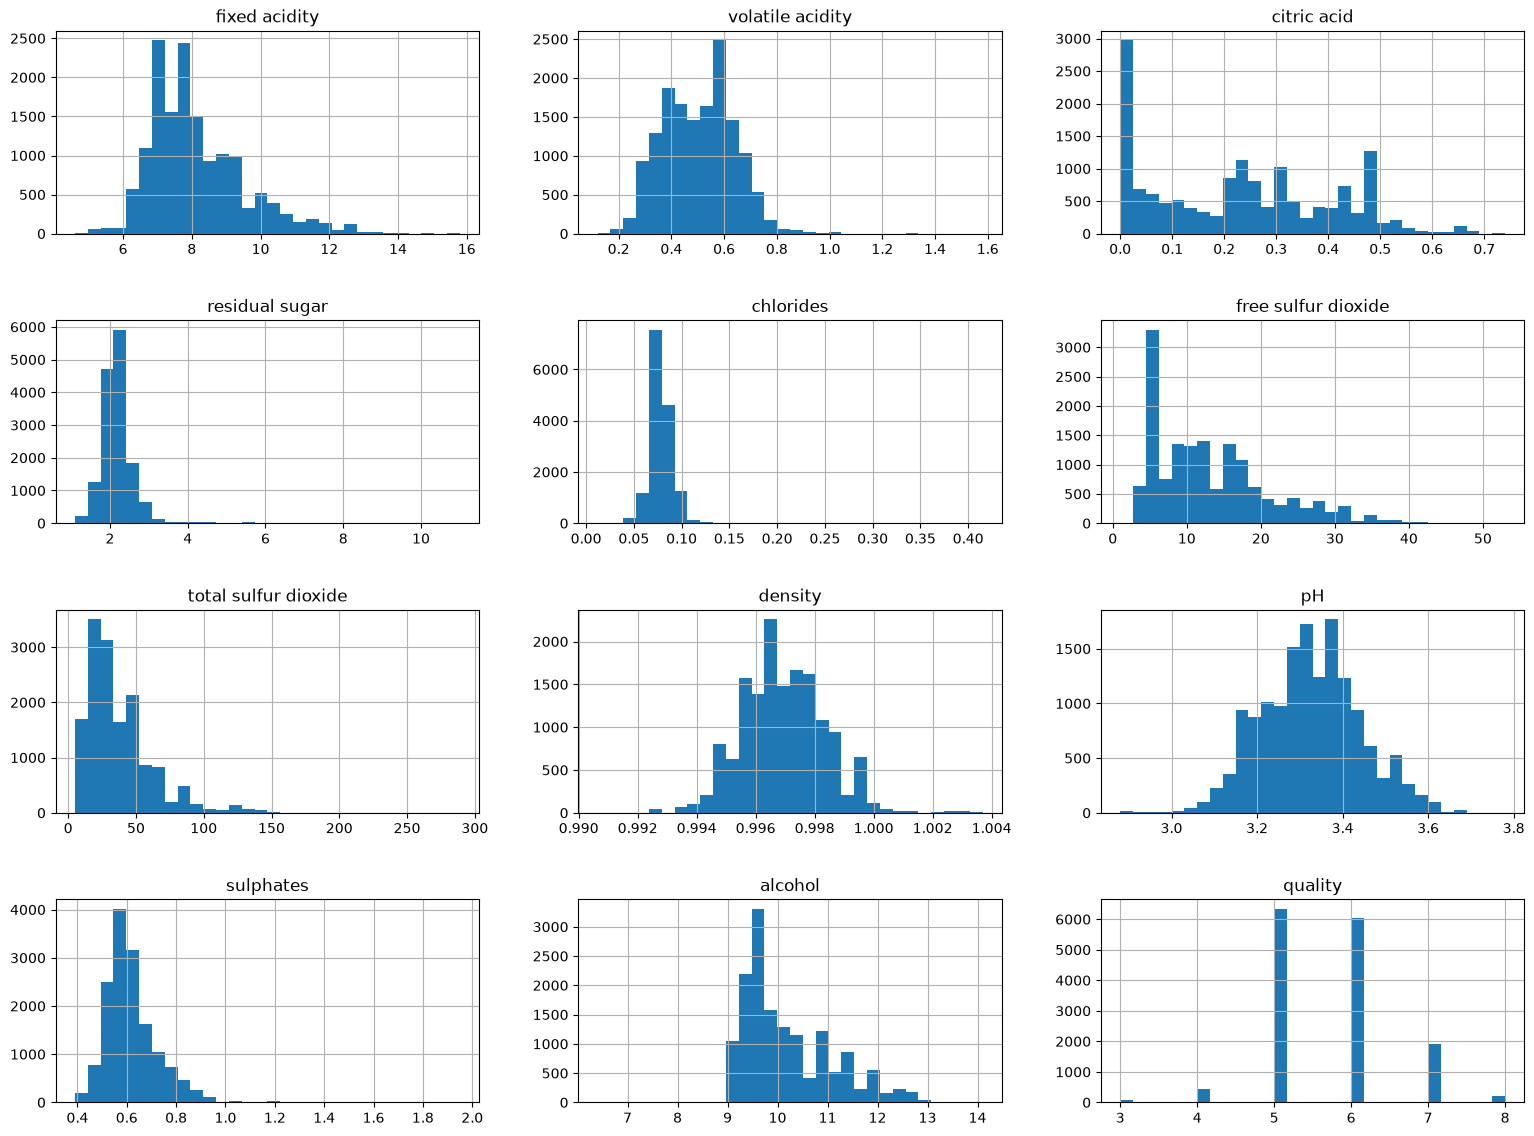

In [18]:
df.drop(columns=['id']).hist(figsize=(16, 12), bins=30, layout=(4,3))
plt.tight_layout(pad=3)
plt.show()

In [19]:
print(df.drop(columns=["id", "quality"]).skew().sort_values(ascending=False).round(2))

chlorides               8.44
residual sugar          4.04
sulphates               1.78
total sulfur dioxide    1.68
fixed acidity           1.11
free sulfur dioxide     1.06
alcohol                 1.03
volatile acidity        0.29
density                 0.27
citric acid             0.25
pH                      0.05
dtype: float64


As features com cauda longa à direita (assimetria > 1) são chlorides (8,44), residual sugar (4,04), sulphates (1,78), total sulfur dioxide (1,68), fixed acidity (1,11), free sulfur dioxide (1,06) e alcohol (1,03). Os casos mais extremos são chlorides e residual sugar, em que poucos valores muito altos puxam a cauda: em chlorides, 75% dos vinhos ficam abaixo de 0,083, mas o máximo chega a 0,415. fixed acidity, free sulfur dioxide e alcohol ficam logo acima do limite.

As aproximadamente simétricas são pH (0,05), citric acid (0,25), density (0,27) e volatile acidity (0,29). Porém citric acid, apesar da assimetria baixa, não tem uma distribuição “bem-comportada”: há um grande acúmulo de valores em 0 e vários picos. A assimetria resume só um aspecto do formato, por isso o histograma é necessário para interpretar o número.

Nas features assimétricas, a média é puxada pela cauda, então a mediana representa melhor o valor típico. Isso vai importar na imputação: preencher valores faltantes com a média distorceria essas variáveis.

# Distribuição das Features

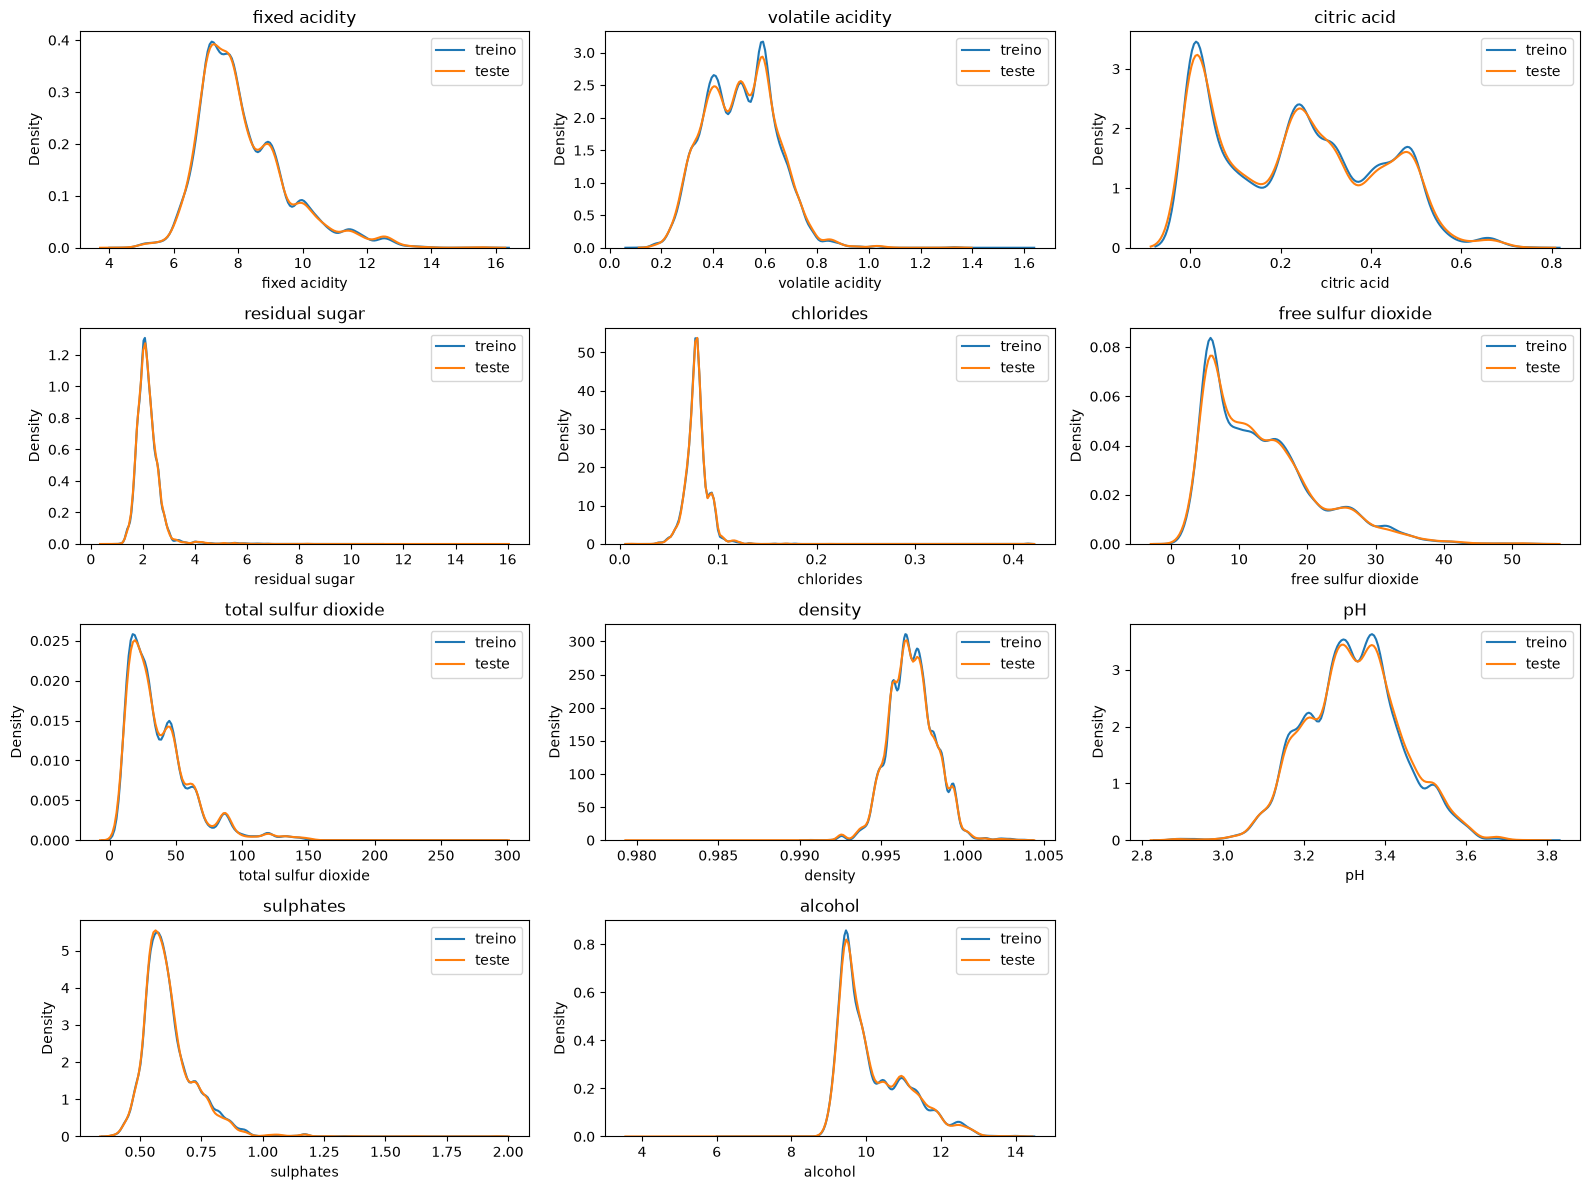

In [20]:
features = df.drop(columns=["id", "quality"]).columns

fig, axes = plt.subplots(4, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, features):
    sns.kdeplot(df[col], ax=ax, label="treino")
    sns.kdeplot(df_test[col], ax=ax, label="teste")
    ax.set_title(col)
    ax.legend()
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

Como as curvas se sobrepõe, temos que teste e treino vêm da mesma distribuição

# Conjunto de Teste

In [21]:
print("Nulos no teste:\n", df_test.isnull().sum())
print("\nDuplicatas no teste:", df_test.drop(columns=["id"]).duplicated().sum())

Nulos no teste:
 id                         0
fixed acidity           2000
volatile acidity        2000
citric acid             2000
residual sugar          2000
chlorides               2000
free sulfur dioxide     2000
total sulfur dioxide    2000
density                 2000
pH                      2000
sulphates               2000
alcohol                 2000
dtype: int64

Duplicatas no teste: 0


In [22]:
# quantos nulos cada linha tem
df_test.isnull().sum(axis=1).value_counts().sort_index()

0     838
1    2359
2    3002
3    2200
4    1101
5     384
6     104
7       8
8       3
9       1
Name: count, dtype: int64

O teste já contém **20% de valores faltantes em cada feature** (2.000 por coluna), e o `id` está completo. A quantidade de nulos por linha segue de perto uma distribuição binomial (n = 11, p = 0,2), o que indica que os nulos foram sorteados de forma aleatória e independente (MCAR).

Apenas 838 linhas (8,4%) estão completas, então remover linhas com nulos não é viável. Além disso, a maioria das linhas tem mais de um nulo, o que justifica uma imputação iterativa, em que as preditoras faltantes são preenchidas provisoriamente e refinadas a cada rodada.

# Resumo da EDA

Qualidade desbalanceada: cerca de 82% dos vinhos têm nota 5 ou 6.


Só alcohol tem correlação relevante com a qualidade (0,43).


Os pares de acidez/pH e de dióxido de enxofre são os mais correlacionados entre si.


7 features têm assimetria > 1, com destaque para chlorides e residual sugar.


O teste tem 20% de nulos aleatórios em cada feature.


Treino e teste têm a mesma distribuição.